In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

print(os.listdir('/content'))

['.config', 'cleaned_adverse_drug_reactions.csv', 'healthcare_patients_sample.csv', 'Synthetic_pharmacy_sales_sample.csv', 'sample_data']


In [6]:
# Display all column names
print("Patient Dataset Columns:")

for col in patients.columns:
    print(col)

Patient Dataset Columns:
PatientID
Age
Gender
Diagnosis
PrimaryMedication
DosageMg
TreatmentDurationDays
Readmitted
BloodPressure
CholesterolLevel


In [7]:
# Find the readmission column automatically
readmission_col = next(
    (col for col in patients.columns
     if 'readmi' in col.lower()),
    None
)

print("Readmission column:", readmission_col)

if readmission_col:
    print("\nReadmission Count:")
    print(patients[readmission_col].value_counts())

    print("\nReadmission Percentage:")
    print(
        patients[readmission_col]
        .value_counts(normalize=True) * 100
    )
else:
    print("Readmission column not found.")

Readmission column: Readmitted

Readmission Count:
Readmitted
No     7
Yes    3
Name: count, dtype: int64

Readmission Percentage:
Readmitted
No     70.0
Yes    30.0
Name: proportion, dtype: float64


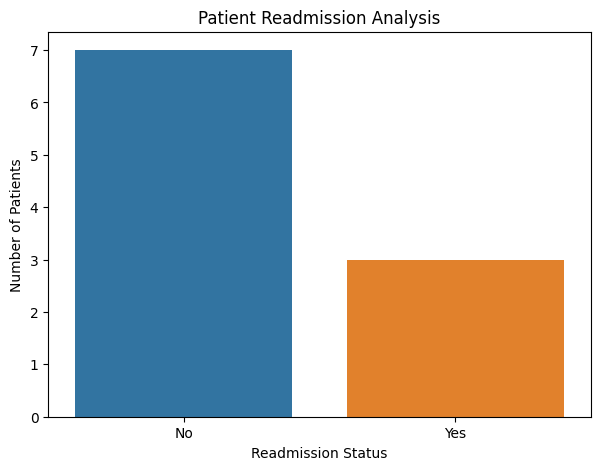

In [8]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=patients,
    x='Readmitted',
    hue='Readmitted',
    legend=False
)

plt.title('Patient Readmission Analysis')
plt.xlabel('Readmission Status')
plt.ylabel('Number of Patients')
plt.show()

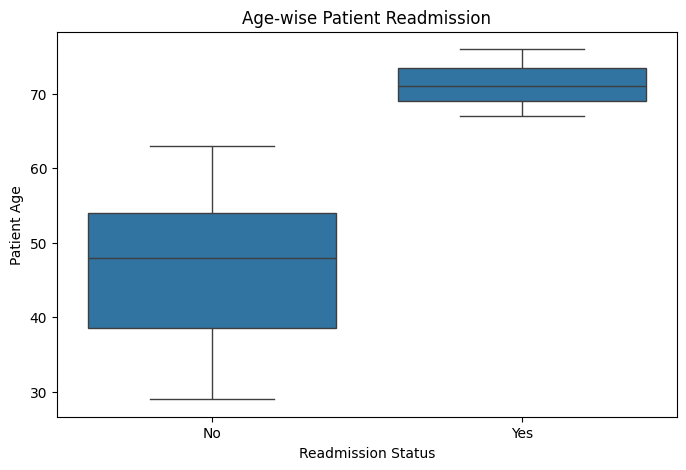

In [9]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=patients,
    x='Readmitted',
    y='Age'
)

plt.title('Age-wise Patient Readmission')
plt.xlabel('Readmission Status')
plt.ylabel('Patient Age')
plt.show()

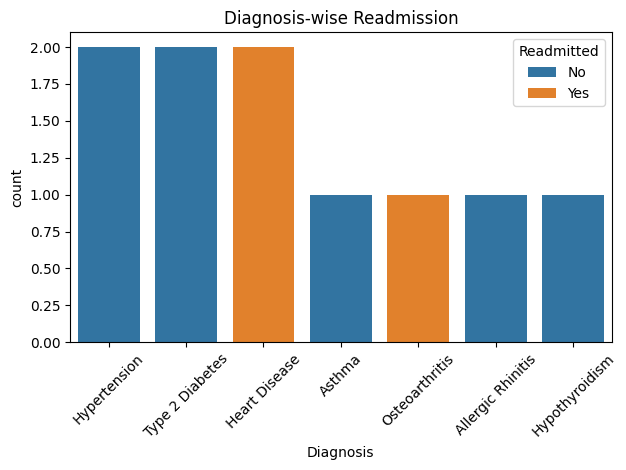

In [10]:
diagnosis_col = next(
    col for col in patients.columns
    if 'diagnos' in col.lower()
)

sns.countplot(
    data=patients,
    x=diagnosis_col,
    hue='Readmitted'
)

plt.title('Diagnosis-wise Readmission')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
# Display pharmacy dataset
display(pharmacy.head())

# Display column names
print("Pharmacy Dataset Columns:")
print(pharmacy.columns.tolist())

# Dataset information
print("\nDataset Information:")
pharmacy.info()

,Date,Product,Category,Brand_Type,Quantity,Sales,Cost,Stock
0,2026-01-03,Paracetamol 500mg,Pain Relief,Generic,120,2400,1440,180
1,2026-01-05,Ibuprofen 200mg,Pain Relief,Branded,65,1950,1170,42
2,2026-01-08,Cetirizine 10mg,Allergy,Generic,90,1350,810,95
3,2026-01-12,Vitamin C 500mg,Vitamins,Branded,48,2400,1440,28
4,2026-01-16,ORS Sachets,Hydration,Generic,110,1650,990,210


Pharmacy Dataset Columns:
['Date', 'Product', 'Category', 'Brand_Type', 'Quantity', 'Sales', 'Cost', 'Stock']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Date        36 non-null     object
 1   Product     36 non-null     object
 2   Category    36 non-null     object
 3   Brand_Type  36 non-null     object
 4   Quantity    36 non-null     int64 
 5   Sales       36 non-null     int64 
 6   Cost        36 non-null     int64 
 7   Stock       36 non-null     int64 
dtypes: int64(4), object(4)
memory usage: 2.4+ KB


In [12]:
# Basic pharmacy statistics
print("Pharmacy Dataset Summary:")
display(pharmacy.describe(include='all'))

Pharmacy Dataset Summary:


,Date,Product,Category,Brand_Type,Quantity,Sales,Cost,Stock
count,36,36,36,36,36.000000,36.000000,36.000000,36.000000
unique,36,9,7,2,NaN,NaN,NaN,NaN
top,2026-01-03,Paracetamol 500mg,Pain Relief,Generic,NaN,NaN,NaN,NaN
freq,1,6,10,18,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,89.194444,2684.722222,1666.944444,65.944444
std,NaN,NaN,NaN,NaN,40.022008,798.153176,540.031425,60.357007
min,NaN,NaN,NaN,NaN,35.000000,1350.000000,810.000000,6.000000
25%,NaN,NaN,NaN,NaN,51.500000,2017.500000,1210.500000,17.500000
50%,NaN,NaN,NaN,NaN,87.000000,2640.000000,1584.000000,40.500000
75%,NaN,NaN,NaN,NaN,120.500000,3315.000000,2142.000000,102.250000


In [13]:
# Pharmacy KPI Analysis

total_sales = pharmacy['Sales'].sum()
total_cost = pharmacy['Cost'].sum()
total_profit = total_sales - total_cost
total_quantity = pharmacy['Quantity'].sum()
total_stock = pharmacy['Stock'].sum()

profit_margin = (total_profit / total_sales) * 100

print("PHARMACY PERFORMANCE REPORT")
print("---------------------------")
print("Total Sales: ₹", total_sales)
print("Total Cost: ₹", total_cost)
print("Gross Profit: ₹", total_profit)
print("Total Quantity Sold:", total_quantity)
print("Total Available Stock:", total_stock)
print("Profit Margin:", round(profit_margin, 2), "%")

PHARMACY PERFORMANCE REPORT
---------------------------
Total Sales: ₹ 96650
Total Cost: ₹ 60010
Gross Profit: ₹ 36640
Total Quantity Sold: 3211
Total Available Stock: 2374
Profit Margin: 37.91 %


Top Selling Medicines:


,Sales
Product,
Paracetamol 500mg,17580
Cough Syrup 100ml,13680
Amoxicillin 250mg,13360
Multivitamin Tablets,12110
Ibuprofen 200mg,9090
Vitamin C 500mg,8700
Antacid Tablets,7880
ORS Sachets,7770
Cetirizine 10mg,6480


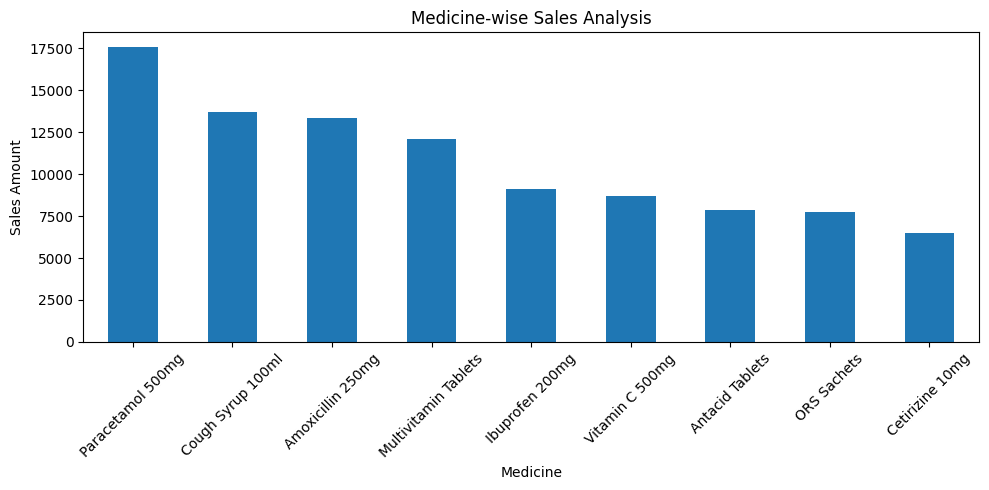

In [14]:
product_sales = pharmacy.groupby(
    'Product'
)['Sales'].sum().sort_values(ascending=False)

print("Top Selling Medicines:")
display(product_sales)

product_sales.plot(
    kind='bar',
    figsize=(10,5),
    title='Medicine-wise Sales Analysis'
)

plt.xlabel("Medicine")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Category-wise Sales:


,Sales
Category,
Pain Relief,26670
Vitamins,20810
Cold & Cough,13680
Antibiotics,13360
Digestive Health,7880
Hydration,7770
Allergy,6480


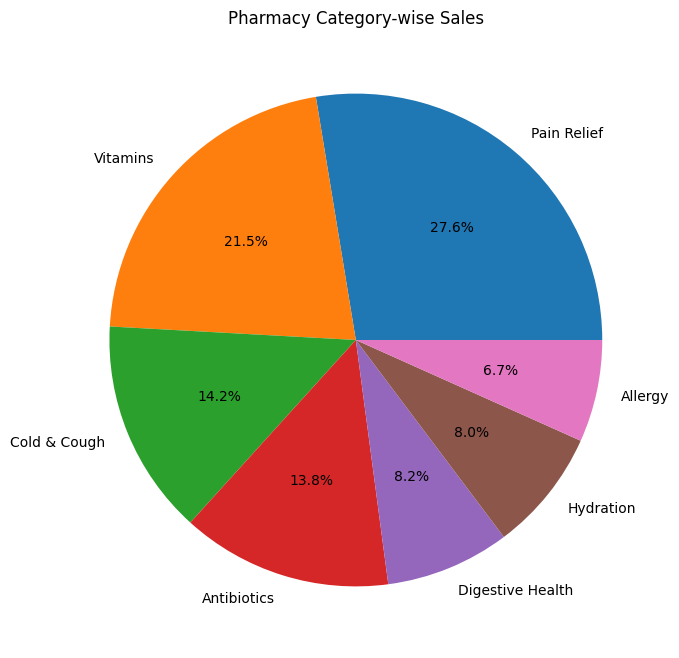

In [15]:
category_sales = pharmacy.groupby(
    'Category'
)['Sales'].sum().sort_values(ascending=False)

print("Category-wise Sales:")
display(category_sales)

category_sales.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(8,8),
    title='Pharmacy Category-wise Sales'
)

plt.ylabel("")
plt.show()

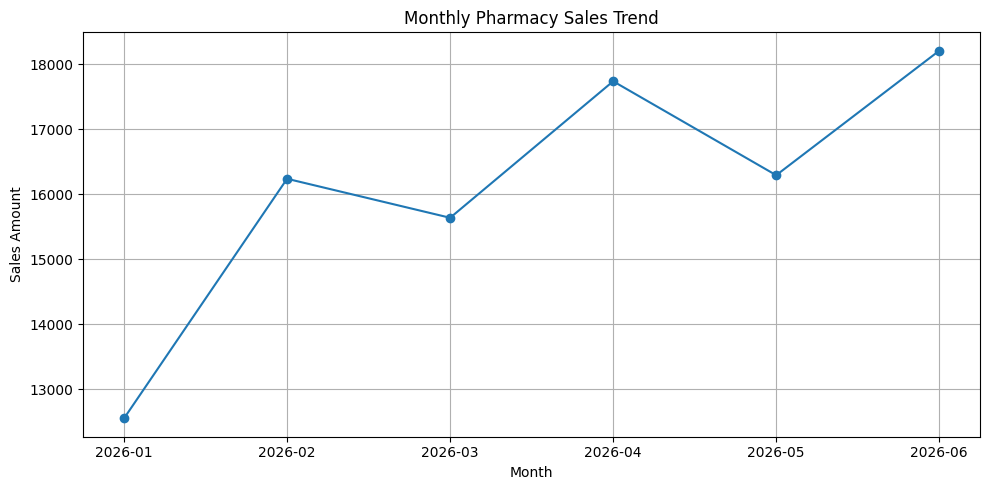

In [16]:
pharmacy['Date'] = pd.to_datetime(pharmacy['Date'])

monthly_sales = pharmacy.groupby(
    pharmacy['Date'].dt.to_period('M')
)['Sales'].sum()

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(10,5))
monthly_sales.plot(marker='o')

plt.title('Monthly Pharmacy Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales Amount')
plt.grid(True)
plt.tight_layout()
plt.show()

# Healthcare Analytics Decision Brief

## 1. Project Objective
To analyse healthcare patient records, pharmacy sales and adverse drug reactions to identify useful operational insights and support better healthcare management decisions.

## 2. Key Findings

### Patient Analysis
- 10 patient records were analysed.
- 7 patients were not readmitted.
- 3 patients were readmitted.
- Readmission rate: 30%.

### Pharmacy Analysis
- 36 pharmacy sales records were analysed.
- Pain Relief was the largest category at 27.6%.
- Vitamins contributed 21.5%.
- Paracetamol 500mg had the highest sales among the displayed medicines.
- June showed the highest monthly sales in the chart.

### Safety Analysis
Add the findings from your adverse drug reaction analysis here.

## 3. Recommendations
- Monitor patient readmission patterns.
- Review pharmacy stock based on sales trends.
- Monitor adverse drug reaction reports.
- Improve data quality and reporting processes.

## 4. Limitations
- The datasets are small and synthetic.
- Findings may not represent actual healthcare populations.
- Correlation does not establish causation.
- Results should not be used as medical advice.
- Patient privacy and data protection must be maintained.

## 5. Conclusion
The analysis demonstrates how healthcare, pharmacy and medicine safety data can support operational decision-making through data analytics and visualization.

In [17]:
import pandas as pd
import glob

# Find the adverse drug reaction CSV
files = glob.glob('/content/*adverse*.csv')

print("Available files:", files)

# Load the cleaned dataset
adverse = pd.read_csv(files[0])

# Display dataset information
print("\nDataset Shape:")
print(adverse.shape)

print("\nColumn Names:")
print(adverse.columns.tolist())

print("\nFirst 5 Records:")
display(adverse.head())

print("\nMissing Values:")
print(adverse.isnull().sum())

Available files: ['/content/cleaned_adverse_drug_reactions.csv']

Dataset Shape:
(8, 10)

Column Names:
['ReportID', 'PatientAge', 'PatientGender', 'SuspectedDrug', 'Indication', 'AdverseReaction', 'ReactionOnsetDays', 'Severity', 'Outcome', 'ReporterType']

First 5 Records:


,ReportID,PatientAge,PatientGender,SuspectedDrug,Indication,AdverseReaction,ReactionOnsetDays,Severity,Outcome,ReporterType
0,ADR-9001,45,Female,Amoxicillin,Bacterial Infection,Skin Rash & Hives,2,Mild,Recovered,Pharmacist
1,ADR-9002,62,Male,Atorvastatin,Hyperlipidemia,Severe Muscle Myalgia,14,Moderate,Recovering,Physician
2,ADR-9003,71,Female,Ciprofloxacin,Uti,Tendonitis,7,Severe,Hospitalized,Physician
3,ADR-9004,28,Male,Ibuprofen,Headache,Gastric Ulcer Bleed,5,Severe,Hospitalized,Patient
4,ADR-9005,53,Female,Lisinopril,Hypertension,Persistent Dry Cough,21,Mild,Recovered,Pharmacist



Missing Values:
ReportID             0
PatientAge           0
PatientGender        0
SuspectedDrug        0
Indication           0
AdverseReaction      0
ReactionOnsetDays    0
Severity             0
Outcome              0
ReporterType         0
dtype: int64


In [18]:

# 1. Top suspected drugs
print("TOP SUSPECTED DRUGS")
drug_counts = adverse['SuspectedDrug'].value_counts()
print(drug_counts)

# 2. Most common adverse reactions
print("\nTOP ADVERSE REACTIONS")
reaction_counts = adverse['AdverseReaction'].value_counts()
print(reaction_counts)

# 3. Severity distribution
print("\nSEVERITY DISTRIBUTION")
severity_counts = adverse['Severity'].value_counts()
print(severity_counts)

# 4. Patient outcomes
print("\nPATIENT OUTCOMES")
outcome_counts = adverse['Outcome'].value_counts()
print(outcome_counts)


TOP SUSPECTED DRUGS
SuspectedDrug
Amoxicillin      1
Atorvastatin     1
Ciprofloxacin    1
Ibuprofen        1
Lisinopril       1
Metformin        1
Warfarin         1
Paclitaxel       1
Name: count, dtype: int64

TOP ADVERSE REACTIONS
AdverseReaction
Skin Rash & Hives          1
Severe Muscle Myalgia      1
Tendonitis                 1
Gastric Ulcer Bleed        1
Persistent Dry Cough       1
Nausea & Diarrhea          1
Uncontrolled Hemorrhage    1
Peripheral Neuropathy      1
Name: count, dtype: int64

SEVERITY DISTRIBUTION
Severity
Mild                3
Moderate            2
Severe              2
Life-Threatening    1
Name: count, dtype: int64

PATIENT OUTCOMES
Outcome
Recovered        3
Hospitalized     3
Recovering       1
Not Recovered    1
Name: count, dtype: int64


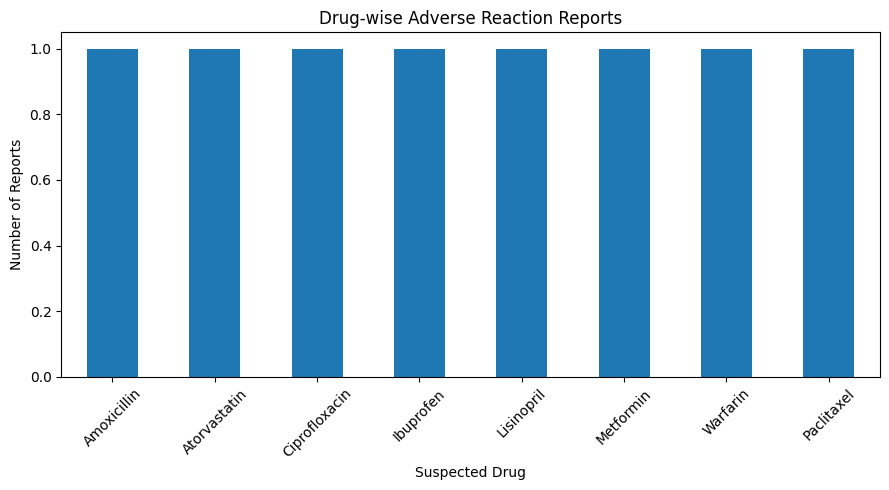

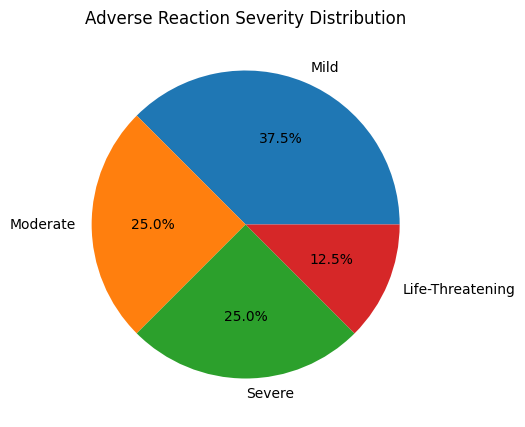

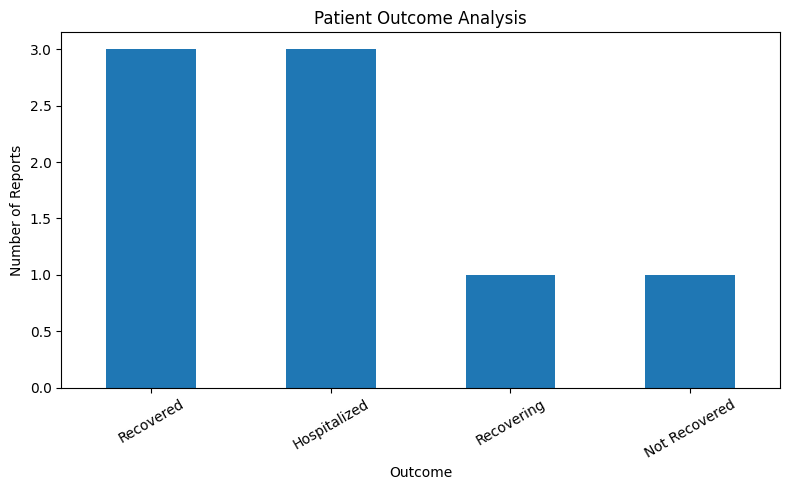

In [19]:

import matplotlib.pyplot as plt

# Drug-wise adverse reaction chart
plt.figure(figsize=(9,5))
drug_counts.plot(kind='bar')
plt.title("Drug-wise Adverse Reaction Reports")
plt.xlabel("Suspected Drug")
plt.ylabel("Number of Reports")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Severity distribution chart
plt.figure(figsize=(7,5))
severity_counts.plot(kind='pie', autopct='%1.1f%%')
plt.title("Adverse Reaction Severity Distribution")
plt.ylabel("")
plt.show()

# Patient outcome chart
plt.figure(figsize=(8,5))
outcome_counts.plot(kind='bar')
plt.title("Patient Outcome Analysis")
plt.xlabel("Outcome")
plt.ylabel("Number of Reports")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [20]:

# Create aggregate CSV files

drug_counts.to_csv('/content/drug_aggregates.csv')
reaction_counts.to_csv('/content/reaction_aggregates.csv')
severity_counts.to_csv('/content/severity_aggregates.csv')
outcome_counts.to_csv('/content/outcome_aggregates.csv')

print("All aggregate CSV files saved successfully!")


All aggregate CSV files saved successfully!
